In [1]:
%pip install -q xgboost

In [4]:
from google.colab import files

uploaded = files.upload()

Saving heart_disease_uci.csv to heart_disease_uci.csv


In [5]:
import pandas as pd
import numpy as np

df = pd.read_csv("heart_disease_uci.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (920, 16)


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [6]:
print("DATA TYPES")
display(df.dtypes.to_frame("Data Type"))

print("\nMISSING VALUES")
display(
    df.isnull().sum()
      .sort_values(ascending=False)
      .to_frame("Missing Count")
)

print("\nTARGET DISTRIBUTION")
display(df["num"].value_counts().sort_index())

print("\nDUPLICATE ROWS:", df.duplicated().sum())

print("\nNUMERICAL SUMMARY")
display(df.describe().T)

DATA TYPES


,Data Type
id,int64
age,int64
sex,object
dataset,object
cp,object
trestbps,float64
chol,float64
fbs,object
restecg,object
thalch,float64



MISSING VALUES


,Missing Count
ca,611
thal,486
slope,309
fbs,90
oldpeak,62
trestbps,59
exang,55
thalch,55
chol,30
restecg,2



TARGET DISTRIBUTION


,count
num,
0,411
1,265
2,109
3,107
4,28



DUPLICATE ROWS: 0

NUMERICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
id,920.0,460.500000,265.725422,1.0,230.75,460.5,690.25,920.0
age,920.0,53.510870,9.424685,28.0,47.00,54.0,60.00,77.0
trestbps,861.0,132.132404,19.066070,0.0,120.00,130.0,140.00,200.0
chol,890.0,199.130337,110.780810,0.0,175.00,223.0,268.00,603.0
thalch,865.0,137.545665,25.926276,60.0,120.00,140.0,157.00,202.0
oldpeak,858.0,0.878788,1.091226,-2.6,0.00,0.5,1.50,6.2
ca,309.0,0.676375,0.935653,0.0,0.00,0.0,1.00,3.0
num,920.0,0.995652,1.142693,0.0,0.00,1.0,2.00,4.0


In [11]:
# Convert the original target into binary classification
df["target"] = (df["num"] > 0).astype(int)

X = df.drop(columns=["id", "dataset", "num", "target"])
y = df["target"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
display(y.value_counts().sort_index())



Feature shape: (920, 13)
Target shape: (920,)

Target distribution:


,count
target,
0,411
1,509


In [12]:

numerical_cols = [
    "age",
    "trestbps",
    "chol",
    "thalch",
    "oldpeak"
]

categorical_cols = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

print("Numerical features:", numerical_cols)
print("Number of numerical features:", len(numerical_cols))

print("\nCategorical features:", categorical_cols)
print("Number of categorical features:", len(categorical_cols))


Numerical features: ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']
Number of numerical features: 5

Categorical features: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
Number of categorical features: 8


In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (736, 13)
X_test: (184, 13)
y_train: (736,)
y_test: (184,)


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

print("Preprocessing pipeline created successfully.")


Preprocessing pipeline created successfully.


In [18]:

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ),
    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        eval_metric="logloss",
        random_state=42
    )
}

trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

    print(f"{name} trained successfully.")


Logistic Regression trained successfully.
Random Forest trained successfully.
XGBoost trained successfully.


In [20]:

import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []

for name, pipeline in trained_models.items():
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).set_index("Model")

display(results_df.round(3))


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Logistic Regression,0.842,0.848,0.873,0.860,0.909
Random Forest,0.870,0.868,0.902,0.885,0.927
XGBoost,0.853,0.844,0.902,0.872,0.917


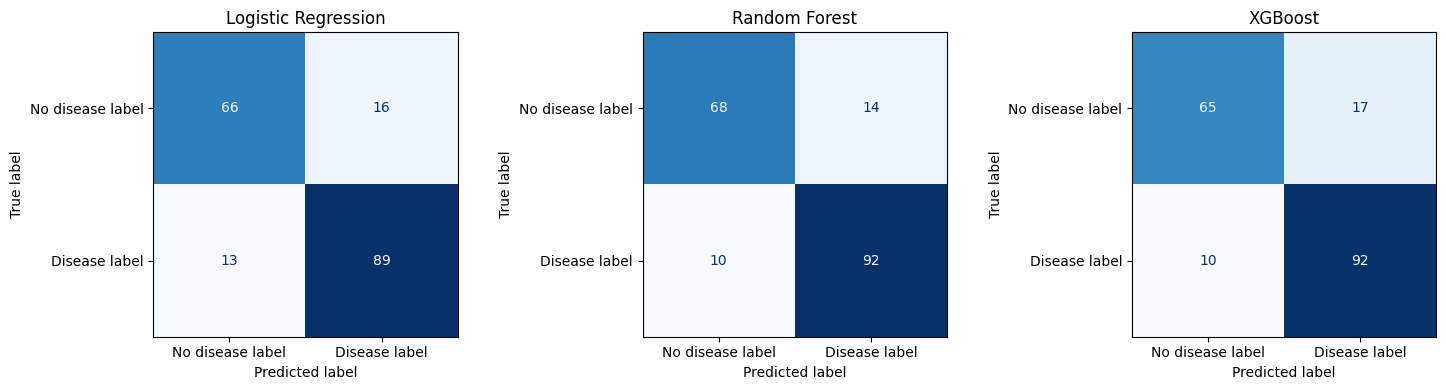

In [21]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, pipeline) in zip(axes, trained_models.items()):
    ConfusionMatrixDisplay.from_estimator(
        pipeline,
        X_test,
        y_test,
        display_labels=["No disease label", "Disease label"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()


In [22]:
from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Model fitting rows:", X_fit.shape[0])
print("Validation rows:", X_val.shape[0])


Model fitting rows: 588
Validation rows: 148


In [23]:
rf_validation = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

rf_validation.fit(X_fit, y_fit)

val_prob = rf_validation.predict_proba(X_val)[:, 1]

print("Validation probabilities:")
print(val_prob[:10])


Validation probabilities:
[0.515 0.88  0.89  0.07  0.045 0.205 0.005 0.375 0.95  0.9  ]


In [24]:
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    val_pred = (val_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, val_pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(3))


,Threshold,Precision,Recall,F1 Score
0,0.30,0.724,0.927,0.813
1,0.35,0.733,0.902,0.809
2,0.40,0.740,0.866,0.798
3,0.45,0.758,0.841,0.798
4,0.50,0.793,0.841,0.817
5,0.55,0.819,0.829,0.824
6,0.60,0.823,0.793,0.807


In [25]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

final_model.fit(X_train, y_train)

print("Final Random Forest trained.")

Final Random Forest trained.


Threshold: 0.3
Accuracy: 0.826
Precision: 0.765
Recall: 0.99
F1-score: 0.863

Classification report:
              precision    recall  f1-score   support

           0       0.98      0.62      0.76        82
           1       0.77      0.99      0.86       102

    accuracy                           0.83       184
   macro avg       0.87      0.81      0.81       184
weighted avg       0.86      0.83      0.82       184



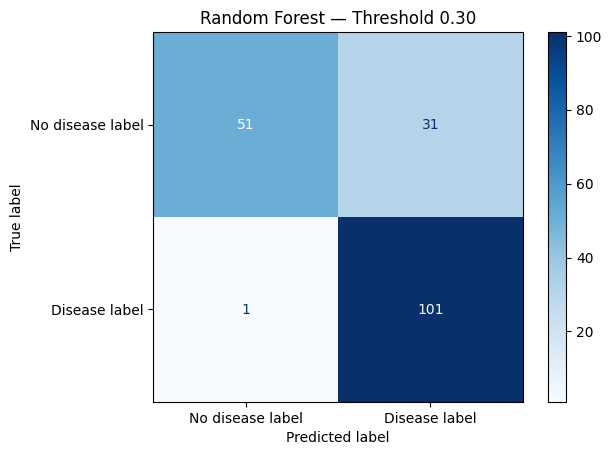

In [27]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import matplotlib.pyplot as plt

# Get positive-class probabilities
test_prob = final_model.predict_proba(X_test)[:, 1]

# Apply the threshold selected on validation data
chosen_threshold = 0.30
test_pred = (test_prob >= chosen_threshold).astype(int)

print("Threshold:", chosen_threshold)
print("Accuracy:", round(accuracy_score(y_test, test_pred), 3))
print("Precision:", round(precision_score(y_test, test_pred), 3))
print("Recall:", round(recall_score(y_test, test_pred), 3))
print("F1-score:", round(f1_score(y_test, test_pred), 3))

print("\nClassification report:")
print(classification_report(y_test, test_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_pred,
    display_labels=["No disease label", "Disease label"],
    cmap="Blues"
)
plt.title("Random Forest — Threshold 0.30")
plt.show()

In [28]:
import joblib
import json
from google.colab import files

# Save the complete pipeline
joblib.dump(final_model, "cardioml_model.joblib")

# Save the threshold separately
with open("model_config.json", "w") as f:
    json.dump({"threshold": 0.30}, f)

print("Model and configuration saved successfully.")

# Download both files to your computer
files.download("cardioml_model.joblib")
files.download("model_config.json")

Model and configuration saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
import joblib
import json
import numpy as np

loaded_model = joblib.load("cardioml_model.joblib")

with open("model_config.json", "r") as f:
    config = json.load(f)

loaded_threshold = config["threshold"]

sample = X_test.iloc[[0]]
probability = loaded_model.predict_proba(sample)[0, 1]
prediction = int(probability >= loaded_threshold)

print("Positive-class probability:", round(probability, 3))
print("Threshold:", loaded_threshold)
print("Predicted class:", prediction)

Positive-class probability: 0.43
Threshold: 0.3
Predicted class: 1


In [31]:
import sklearn
print(sklearn.__version__)

1.6.1
